# Brain MRI Project

!!! TO DO NEXT : 
1) STACK HBG WITH GAUSSIAN ARD 
2) STACK VERTICAL OUTLIERS (huber/ransac) WITH FEATURE OUTLIERS ()
3) ADD HUBER OR RANSAC AS METHOD VAL FROZEN

## 0) Usefull things, imports

In [61]:
#load the autoreload extension (magic command, only for IPython)
%load_ext autoreload
#before each cell, re-execute any imported module whose file changed on disk
%autoreload 2

import os
os.environ["OMP_NUM_THREADS"] = "1"
from datetime import datetime

import numpy as np
import pandas as pd

# --- model selection / evaluation
from sklearn.model_selection import KFold, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score

# --- scaling
from sklearn.preprocessing import StandardScaler, RobustScaler

# --- imputation
from sklearn.experimental import enable_iterative_imputer   # noqa: F401  (must precede the next line)
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer

# --- outlier detection (sklearn: +1 inlier / -1 outlier)
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.covariance import EllipticEnvelope, MinCovDet
from sklearn.svm import OneClassSVM

# --- outlier detection (PyOD: 0 inlier / 1 outlier)  -- pip install pyod
from pyod.models.ecod import ECOD
from pyod.models.copod import COPOD

# --- feature selection
from sklearn.feature_selection import (
    VarianceThreshold, SelectKBest, SelectFromModel,
    f_regression, mutual_info_regression, RFE, RFECV,
)

# --- models
from sklearn.linear_model import Ridge, Lasso, ElasticNet, HuberRegressor
from sklearn.cross_decomposition import PLSRegression
from sklearn.base import BaseEstimator, RegressorMixin, clone, is_regressor

from sklearn.ensemble import HistGradientBoostingRegressor, StackingRegressor
from sklearn.linear_model import LinearRegression   #meta model of the stacking

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, ConstantKernel

from sklearn.linear_model import RANSACRegressor, Ridge


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1) Loading data


In [62]:

X_train_df = pd.read_csv('./data/X_train.csv', skiprows=1, header=None)
y_train_df = pd.read_csv('./data/y_train.csv', skiprows=1, header=None)
X_test_df = pd.read_csv('./data/X_test.csv', skiprows=1, header=None)

# drop the id column
X_train = X_train_df.values[:, 1:]
y_train = y_train_df.values[:, 1:]
X_test = X_test_df.values[:, 1:]
print(X_train.shape, y_train.shape, X_test.shape)

print(np.isnan(X_test).sum().sum())

#remember to normalize before using methods

(1212, 832) (1212, 1) (776, 832)
40634


# 2) Preprocessing

## A) Dropping low data features (filter)

In [63]:
#inspection
pd.Series(np.isnan(X_train).mean(axis=1)).sort_values(ascending=False)
pd.Series(np.isnan(X_train).mean(axis=0)).sort_values(ascending=False)

#no clear break in the distribution of missing values (seems to be a binomial distribution), so we will not remove any rows or columns

79     0.099835
381    0.098185
734    0.097360
313    0.097360
463    0.096535
         ...   
84     0.056931
728    0.056106
425    0.056106
151    0.054455
703    0.053630
Length: 832, dtype: float64

## B) Remove outliers

The mean and variance/covariance are contaminated by the outliers => must remove outliers before converting the Nans, otherwise we fit information that's not from the data set.

But to find the outliers we must first eliminate Nans temporarly with a method robust to the outliers (eg median).

!!! test set has no outliers => check if letting outliers or not in validation test affects score (could lead to higher lambdas in ridge), if yes then remove outliers from it too, but careful of degenerate incentive (method of removing outlier tuned from validation => validation set changes with it => exam gets shorter and easier) => fixed method for validation for identical exam for each candidate



In [ ]:
#we will iterate over different methods to remove outliers and keep the one that scores the best
#note : we ll start with just a few not too heavy methods and then add if needed. Methods are stored in order of their complexity, 'l' is the nb of methods used
l_train = 5
l_val = 2

#isolation forest type dont find vertical outliers (dont depend on y), need huberregressor/Ransac
#large alpha for huber/ransac : with d=832 ~ n a weak penalty interpolates the training set => residuals ~0 => 3*MAD flags ~30% of the data
#alpha=1000 => in-sample residual scale ~ out-of-fold one (6.4 vs 7.1 years) => out-of-fold residuals tested, no gain (0.629 vs 0.628)
#ransac : default residual_threshold = MAD(y) = 6 years < residual noise (~7 years) => flags ~30%, fixed to ~3 residual std = 20 years
#stacked detector : combines feature outliers (X only, eg ECOD) with vertical outliers (y|X, eg Huber/RANSAC)
#a sample is removed if ANY of the sub-detectors flags it (keep = AND of the keep masks, see keep_mask)
class StackedDetector(BaseEstimator):
    def __init__(self, detectors=None):
        self.detectors = detectors

    def fit(self, X, y=None):
        #regressors (vertical outliers) need y, unsupervised detectors dont (avoids the PyOD warning)
        self.detectors_ = [clone(d).fit(X, y) if is_regressor(d) else clone(d).fit(X) for d in self.detectors]
        return self

    def __repr__(self):
        #short readable name, otherwise all stacked detectors look the same once truncated in the analysis
        return "Stacked(" + " + ".join(type(d).__name__ for d in self.detectors) + ")"

out_methods_train = [
    ECOD(contamination=0.05),          #parameter-free, fast        [PyOD]
    RANSACRegressor(estimator=Ridge(alpha=1000.0), min_samples=0.5,
                    residual_threshold=20.0, max_trials=100, random_state=0),
    HuberRegressor(epsilon=1.35, alpha=1000.0, max_iter=500),
    StackedDetector([ECOD(contamination=0.05), HuberRegressor(epsilon=1.35, alpha=1000.0, max_iter=500)]),   #feature + vertical outliers
    StackedDetector([ECOD(contamination=0.05), RANSACRegressor(estimator=Ridge(alpha=1000.0), min_samples=0.5,
                                                               residual_threshold=20.0, max_trials=100, random_state=0)]),
    #IsolationForest(contamination=0.05, random_state=0),  # 1. best-matched to high d, O(n log n)

    COPOD(contamination=0.05),                        # 3. parameter-free, sees dependence [PyOD]
    LocalOutlierFactor(n_neighbors=20, novelty=True,
                       contamination=0.05),                 # 5. only if intrinsic dim is low
    EllipticEnvelope(contamination=0.05, random_state=42),  # 6. Mahalanobis+MCD — needs d reduced first
    OneClassSVM(nu=0.05, kernel="rbf", gamma="scale"),      # 7. expensive, no contamination param
    "robust_residuals",                                     # 8. Huber fit + large residuals — to do
]

out_methods_val = [
    None,                                                    # dirty validation
    HuberRegressor(epsilon=1.35, alpha=1000.0, max_iter=500),     # frozen referee — chosen once, never tuned
    RANSACRegressor(estimator=Ridge(alpha=1000.0), min_samples=0.5,
                    residual_threshold=20.0, max_trials=100, random_state=0),   # frozen referee, alternative
]
out_methods_val_names = ["None on validation: ", "Huber on validation: ", "RANSAC on validation: "]

#the following was my original architecture. I changed to a wrapper class to use it inside gridsearchcv
#First eliminate the nans with a method robust to outliers (only to find them) : impute median
def nan_to_median(X_train):
    X_median = np.nanmedian(X_train, axis=0, keepdims=True)
    X_mask = np.isnan(X_train)
    X_train = np.where(X_mask, X_median, X_train)

    return (X_train, X_mask), X_median

#below are old helpers i built
"""
#outliers of val removed independently of the train set, to avoid data leakage
def remove_outliers_val(X_val, val_maskmethod_val):
    if method_val is None:
        return X_val
    #remove outliers using the method
    return X_val

#outliers of train fune-tuned to the val set
def remove_outliers_train(X_train, y_train, train_mask, method_train):
    #remove outliers using the method
    return X_train

#after removing outliers, we put the nans back for conditionnal imputation
def replace_nans(X, mask):
    return np.where(mask, np.nan, X)

def remove_outliers(method_train, method_val, X_train, y_train, X_val):
    (X_train, train_mask), (X_val, val_mask) = nan_to_median(X_train, X_val)

    X_val, val_mask = remove_outliers_val(X_val, val_mask, method_val)
    X_train, y_train, train_mask = remove_outliers_train(X_train, y_train, train_mask,method_train)

    X_train, X_val = replace_nans(X_train, train_mask), replace_nans(X_val, val_mask)

    return X_train, X_val
"""

#wrapper class to use this outlier removal methods inside gridsearchcv
class OutlierRemover(BaseEstimator, RegressorMixin):
    def __init__(self, inner=None, detector=None, referee=None, contamination=0.05):
        self.inner = inner
        self.detector = detector
        self.referee = referee
        self.contamination = contamination
        self.med =None

    def fit(self, X, y):
        #impute nans with median (robust to outliers)
        (X_clean, X_nan_mask), med = nan_to_median(X)
        self.med_ = med

        self.scaler_ = RobustScaler().fit(X_clean) #needed for huber/ransac, stored to scale the validation set the same way in the scorer
        X_scaled = self.scaler_.transform(X_clean)

        #outlier removal of validation set (fit on training set to avoid leakage, method frozen to keep the same exam)
        if self.referee is not None:
            self.referee_ = clone(self.referee).fit(X_scaled, y)
        else :
            self.referee_ = None

        #outlier removal of training set
        detector = clone(self.detector)

        # map self.contamination to the appropriate parameter name for the detector (for a stacked detector : each of its sub-detectors)
        sub_detectors = detector.detectors if isinstance(detector, StackedDetector) else [detector]
        for d in sub_detectors:
            valid_params = d.get_params()
            if 'contamination' in valid_params:
                d.set_params(contamination=self.contamination)
            elif 'nu' in valid_params:
                d.set_params(nu=self.contamination)

        detector.fit(X_scaled, y) #remove outliers
        keep = keep_mask(detector, X_scaled, y) #value of outlier depends on the detector
        self.inner_ = clone(self.inner).fit(X[keep], y[keep])

        return self

    def predict(self, X):
        return self.inner_.predict(X)


#on_val=True when the detector is the frozen referee applied on the validation set (not the set it was fitted on)
def keep_mask(detector, X, y=None, on_val=False):
    detector_name = type(detector).__name__
    # PyOD estimators belong to the 'pyod' module and expose 'decision_scores_'
    is_pyod = type(detector).__module__.startswith('pyod') or hasattr(detector, 'decision_scores_')

    keep = np.ones(X.shape[0], dtype=bool)
    if is_pyod:
        # PyOD convention: 0 = inlier, 1 = outlier
        keep = (detector.predict(X) == 0)
    elif detector_name == 'StackedDetector':
        #kept only if every sub-detector keeps it (feature outliers AND vertical outliers removed)
        keep = np.all([keep_mask(d, X, y, on_val) for d in detector.detectors_], axis=0)
    elif detector_name == 'RANSACRegressor' and not on_val:
        keep = detector.inlier_mask_   #only valid on the set RANSAC was fitted on
    elif detector_name in ('HuberRegressor', 'RANSACRegressor'):
        #vertical outliers : residual larger than 3 robust std (MAD) w.r.t. the robust fit (RANSAC doesnt store its threshold => same rule on validation)
        signed_residuals = y - detector.predict(X)
        scale = 1.4826 * np.median(np.abs(signed_residuals - np.median(signed_residuals)))
        threshold = max(3.0 * scale, 1e-5)
        keep = (np.abs(signed_residuals) <= threshold)

    else:
        # Scikit-learn convention: 1 = inlier, -1 = outlier
        keep = (detector.predict(X) == 1)


    #Check we aren't deleting most of the dataset due to a configuration error
    if keep.mean() < 0.5:
        raise ValueError("More than 50% of the data was flagged as outliers, check the detector configuration.")
    return keep


#outlier removal of the validation set directly in the scorer here !
def frozen_referee_as_scorer():

    def frozen_referee_r2(estimator, X_val, y_val, out_method_val=None):
        if estimator.referee_ is None:
            keep = np.ones(len(y_val), dtype=bool)
        else:
            X   = np.where(np.isnan(X_val), estimator.med_, X_val)   # training medians
            X   = estimator.scaler_.transform(X)                     # training scaler, same space the referee was fitted in
            keep = keep_mask(estimator.referee_, X, y_val, on_val=True)   # huber/ransac need y_val (vertical outliers)
        return r2_score(y_val[keep], estimator.predict(X_val[keep]))

    return frozen_referee_r2


## C) Impute Nans

1) Constant imputation : eg replacing by the mean : reduces the variance by (1-p)sj^2 with p the fraction replaced, and covariance. Prediction pulled towards the mean (biais attenuation). Might give impossible values (eg feature surface and volume physically impossible together)
2) Conditionnal imputation : predict missing values from other features (keep correlation structure) -> Better
eg : KNNImputer (avg k similar subjects) ; IterativeImputer (regress each feature on the others)



In [65]:
l_impute = 1

imputation_methods = [
    SimpleImputer(strategy="median"),            # 1. baseline 
    "passthrough", #some models can handle nans directly
    #KNNImputer(n_neighbors=5), KNNImputer(n_neighbors=20), KNNImputer(n_neighbors=100),     #no significant improvement
    IterativeImputer(max_iter=5, random_state=42),  # 3. conditional, expensive at d=832
]

def impute_naans(method, X_train, X_val, X_test=None):
    #impute the nans using the method
    return X_train, X_val, X_test

## D) Feature selection

Why SVD fails:

Total intracranial volume varies enormously across subjects — and is essentially age-independent (skull size is set in childhood).
Ventricular volume varies much less — and is one of the strongest age markers (ventricles enlarge with age).

PC1 is then dominated by head size. Truncate to 10 components might even delete the ventricular volume component.
Irrelevant features were added => If they have substantial variance, SVD ranks them first. (+any outlier left can have high variance)

In [66]:
l_feature_indep_y = 1
l_feature_dep_y = 4

feature_methods_indep_y = [
    VarianceThreshold(threshold=0.0),   # drops constant columns
    "correlation_pruning",              # to do
]

feature_methods_dep_y = [
    SelectKBest(f_regression, k=150), #best found
    #SelectKBest(f_regression, k=120), 
    SelectFromModel(ElasticNet(alpha=0.01, l1_ratio=0.5)), SelectFromModel(ElasticNet(alpha=0.1, l1_ratio=0.5)), SelectFromModel(ElasticNet(alpha=1, l1_ratio=0.5)),  # embedded — the best-matched one
    VarianceThreshold(0.0),
    RFE(Ridge(alpha=1.0), n_features_to_select=100, step=0.1),  # expensive, add later
]
#PLS later? (covariance with y truncates irrelevant features)

def feature_selection(X_train, y_train, X_val, X_test, method_indep_y, method_dep_y):
    #apply the methods to select features
    return X_train, X_val, X_test

## E) Model

We use ridge regression because ordinary linear regression highhly underestimates the variance on the training set (s^2(1-d/n) vs s^2(1+d/n) for an indep test set) and multicolinearity (like for n>~d) makes the det~0 => analytical solution can diverge (the solution is a whole subspace)

In [67]:
#models are iterated on, i put the different hyperparameters here for now, not ideal but avoids needing to unify model__para for different models with different parameters in gridsearchcv
l_models = 2

#gaussianprocess reg with ARD kernel, length scale is a vector of size k (the number of features) => weights each feature differently
def gp(k, ls=10.0):
    return GaussianProcessRegressor(
        kernel=ConstantKernel(1.0) * RBF(length_scale=np.full(k, ls)) + WhiteKernel(1.0),
        normalize_y=True, random_state=42)

#stacking : HGB captures the non linear couplings/thresholds, GP ARD the smooth part => out-of-fold predictions combined by a linear meta model
def stack_hgb_gp(k_gp=20):
    hgb = HistGradientBoostingRegressor(max_iter=600, learning_rate=0.05, early_stopping=False, random_state=42,
                                        l2_regularization=10.0, min_samples_leaf=20, max_features=0.2, max_leaf_nodes=15)  #best params found with the HGB subgrid
    gp_ard = Pipeline([("select", SelectKBest(f_regression, k=k_gp)),   #GP needs its own feature count, pinned to the kernel dimension
                       ("gp", gp(k_gp))])
    return StackingRegressor(estimators=[("hgb", hgb), ("gp", gp_ard)],
                             final_estimator=LinearRegression(positive=True),   #non negative weights ~ weighted average of the 2 models
                             cv=5)   #meta model fitted on out-of-fold predictions (avoids trusting the overfitted HGB)

#after some testing, linear class models are not performing well => need non linear couplings
models = [
    HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, early_stopping=True, random_state=42, n_iter_no_change=20),   # the best-matched one, robust to outliers, can handle nans directly
    #HuberRegressor(epsilon=1.35, alpha=1e-4),   # the robust-loss arm of the 2×2
    #PLSRegression(n_components=20),             # only after outlier removal
]

# each entry is a self-contained sub-grid
model_subgrids = [
    # HGB: feature count free, carries its own depth-3 params
    #more regularization tested (max_leaf_nodes=7, min_samples_leaf=40, lower learning rate) => lower val score, only the train score drops
    #train/val gap is not reduced by regularizing => plateau ~0.625, l2=10 and 600 iterations slightly better (within fold noise)
    {"inner__model":   [HistGradientBoostingRegressor(max_iter=600, learning_rate=0.05,
                                                      early_stopping=False, random_state=42)
                                                      ],
     "inner__feature": feature_methods_indep_y[:l_feature_indep_y] + feature_methods_dep_y[:l_feature_dep_y],
     "inner__model__l2_regularization": [10.0],
     "inner__model__min_samples_leaf": [5, 10, 20],
     "inner__model__max_features": [0.1, 0.2],
     "inner__model__max_leaf_nodes":    [15]},

    # GP ARD: feature count PINNED to the kernel dimension
    {"inner__model": [gp(20)], "inner__feature": [SelectKBest(f_regression, k=20)]},
    {"inner__model": [gp(50)], "inner__feature": [SelectKBest(f_regression, k=50)]},

    # Stacking HGB + GP ARD: HGB params frozen to the best found, HGB sees the 150 selected features, GP re-selects its k inside
    {"inner__model":   [stack_hgb_gp(k_gp=20)],      #stack_hgb_gp(k_gp=50) possible but heavy (ARD gradient is n x n x k)
     "inner__feature": [SelectKBest(f_regression, k=150)]},
]

l_subgrids = 4          # ← your single knob, same role as l_models (1 = HGB, 2-3 = GP ARD, 4 = stacking HGB + GP ARD)

#("model", RidgeCV(alphas=np.logspace(-3, 4, 15))) can be used to sweep different alphas for ridge fast

## F) Pipeline settings, parameters to tune

In [68]:
#pipeline (each step can be replaced by a different method, to be tuned with grid search)


pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")), #only one now, will be replaced by grid search from the grid (clone)
    ("scale",  StandardScaler()),
    ("feature", SelectKBest(f_regression, k=100)),
    ("model",  Ridge(alpha=1.0)),
])

#parameter grid for grid search (found using pipe.get_params().keys())
#referee outisde the grid (frozen) to have the same exam
grid = {
    #depth 1:
    "detector":      out_methods_train[:l_train],
    "contamination":   [0.05],
    **model_subgrids[l_subgrids - 1],  #paremeters to tune depend on the model used
    #depth 2 (para of the inner pipeline):
    "inner__impute":  imputation_methods[:l_impute],
}

## G) Train the model and predict

In [69]:
results = {}
kf = KFold(5, shuffle=True, random_state=42)

for name, referee in zip(out_methods_val_names[:l_val], out_methods_val[:l_val]):
    search = GridSearchCV(
        OutlierRemover(inner=pipe, detector=IsolationForest(), referee=referee),
        grid, scoring=frozen_referee_as_scorer(), cv=kf,
        n_jobs=-1, verbose=2, error_score=np.nan, return_train_score=True,
    )
    search.fit(X_train, y_train.ravel())

    results[name] = search

Fitting 5 folds for each of 90 candidates, totalling 450 fits


c:\Users\mathi\Desktop\ACADEMIC\Zurich\AML\Project - Brain Age\brain-age\.venv\Lib\site-packages\pyod\models\base.py:555: UserWarning: y should not be presented in unsupervised learning.
  warnings.warn(


## H) Analyse

In [70]:
print(name, search.best_params_)

best = results["None on validation: "].best_estimator_      #need to check the best one first
y_pred = best.predict(X_test)

s = results["None on validation: "]; i = s.best_index_
print(s.cv_results_["mean_train_score"][i], s.cv_results_["mean_test_score"][i])
df = pd.DataFrame(s.cv_results_)
# readable labels instead of object reprs
for col in ["detector", "inner__impute", "inner__feature", "inner__model"]:
    df[col] = [str(p[col])[:55] for p in df["params"]]

# best score achieved by any candidate using each value
for col in ["detector", "inner__impute", "inner__feature", "inner__model"]:
    print("="*70)
    print(df.groupby(col)["mean_test_score"]
            .agg(best="max", mean="mean", n="size")
            .sort_values("best", ascending=False).round(4))

i_dirty = results["None on validation: "].best_index_   #same grid for every referee => same candidate index
for name, s in results.items():
    print(name, "best:", round(s.best_score_, 4), s.best_params_)
    # same configuration, scored under both protocols:
    print("  score of the dirty-protocol winner under this protocol:", round(s.cv_results_["mean_test_score"][i_dirty], 4))

print(y_pred.min(), y_pred.max(), y_pred.std())
print(y_train.min(), y_train.max(), y_train.std())


None on validation:  {'contamination': 0.05, 'detector': ECOD(contamination=0.05, n_jobs=1), 'inner__feature': SelectKBest(k=150, score_func=<function f_regression at 0x000002B2C6968AE0>), 'inner__impute': SimpleImputer(strategy='median'), 'inner__model': HistGradientBoostingRegressor(early_stopping=False, learning_rate=0.05,
                              max_iter=300, random_state=42), 'inner__model__l2_regularization': 1.0, 'inner__model__max_features': 0.2, 'inner__model__max_leaf_nodes': 15, 'inner__model__min_samples_leaf': 20}
0.9235893373069134 0.5419857304977762
                                                      best    mean   n
detector                                                              
ECOD(contamination=0.05, n_jobs=1)                  0.5420  0.4956  30
RANSACRegressor(estimator=Ridge(), min_samples=...  0.4926  0.4585  30
HuberRegressor(max_iter=500)                        0.4832  0.4467  30
                                   best    mean   n
inner__impute   

## I) Submission

(776, 2)    id          y
0   0  60.380214
1   1  77.140593
2   2  71.107940
3   3  75.818734
4   4  73.881066


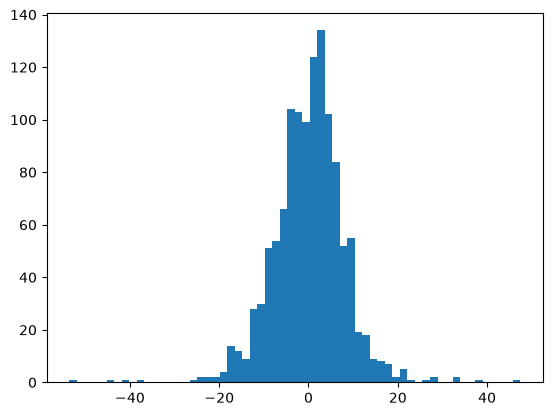

[21.38940094 21.55624604 21.9904172  22.15788761 22.16056114 23.71555835
 23.7671757  24.37330779 25.39715641 26.64022136 27.35128294 27.99136589
 33.43870362 33.69676164 36.879203   38.84544902 41.43769103 45.11003031
 47.41028837 53.57811159]


In [71]:
os.makedirs("submissions", exist_ok=True)           


submission = pd.DataFrame({"id": np.arange(len(y_pred)), "y": y_pred.ravel()})
submission.to_csv(f"submissions/sub_{datetime.now():%m%d_%H%M}.csv", index=False)
print(submission.shape, submission.head())

from sklearn.model_selection import cross_val_predict
oof = cross_val_predict(pipe, X_train, y_train.ravel(), cv=kf)
res = y_train.ravel() - oof
import matplotlib.pyplot as plt; plt.hist(res, bins=60); plt.show()
print(np.sort(np.abs(res))[-20:])